Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter

Load the processed data

In [2]:
X_train = pd.read_csv(
    "../data/processed/X_train_processed.csv"
)

X_test = pd.read_csv(
    "../data/processed/X_test_processed.csv"
)

y_train = pd.read_csv(
    "../data/processed/Y_train.csv"
).squeeze()

y_test = pd.read_csv(
    "../data/processed/Y_test.csv"
).squeeze()

Veryfing Sizes 

In [3]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("Y_train:", y_train.shape)
print("Y_test:", y_test.shape)

X_train: (16000, 70)
X_test: (4000, 70)
Y_train: (16000,)
Y_test: (4000,)


Check the call distribution

In [4]:
print("Training target distribution")
print(y_train.value_counts())

print("\nTraining tatget precentage")
print(y_train.value_counts(normalize=True) * 100)

Training target distribution
loan_paid_back
1    12798
0     3202
Name: count, dtype: int64

Training tatget precentage
loan_paid_back
1    79.9875
0    20.0125
Name: proportion, dtype: float64


In [5]:
print("Testing target distibution")
print(y_test.value_counts())

print("Testing traget precentage")
print(y_test.value_counts(normalize=True)*100)

Testing target distibution
loan_paid_back
1    3200
0     800
Name: count, dtype: int64
Testing traget precentage
loan_paid_back
1    80.0
0    20.0
Name: proportion, dtype: float64


Visualize the imbalance

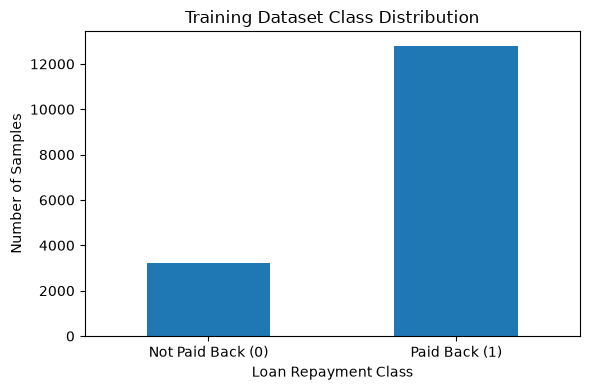

In [6]:
class_counts = y_train.value_counts().sort_index()

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar")

plt.xlabel("Loan Repayment Class")
plt.ylabel("Number of Samples")
plt.title("Training Dataset Class Distribution")
plt.xticks(
    ticks=[0, 1],
    labels=["Not Paid Back (0)", "Paid Back (1)"],
    rotation=0
)

plt.tight_layout()
plt.show()

Baseline Model Using Original Class Distribution

In [7]:
from sklearn.linear_model import LogisticRegression

In [8]:
baseline_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_lr.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

Evaluate the baseline

In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [10]:
y_pred_baseline = baseline_lr.predict(X_test)
y_prob_baseline = baseline_lr.predict_proba(X_test)[:, 1]

Baseline of logistic regression

In [11]:
print("Baseline Logistic Regression")

print("Accuracy :", accuracy_score(y_test, y_pred_baseline))
print("Precision:", precision_score(y_test, y_pred_baseline))
print("Recall   :", recall_score(y_test, y_pred_baseline))
print("F1 Score :", f1_score(y_test, y_pred_baseline))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_baseline))

Baseline Logistic Regression
Accuracy : 0.88675
Precision: 0.9007878611030056
Recall   : 0.9646875
F1 Score : 0.9316432775011317
ROC-AUC  : 0.8853921875


In [12]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_baseline))


Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.57      0.67       800
           1       0.90      0.96      0.93      3200

    accuracy                           0.89      4000
   macro avg       0.85      0.77      0.80      4000
weighted avg       0.88      0.89      0.88      4000



Class-Weighted Logistic Regression

In [13]:
weighted_lr = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

weighted_lr.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [14]:
y_pred_weighted = weighted_lr.predict(X_test)
y_prob_weighted = weighted_lr.predict_proba(X_test)[:, 1]

In [15]:
print("Class-Weighted Logistic Regression")

print("Accuracy :", accuracy_score(y_test, y_pred_weighted))
print("Precision:", precision_score(y_test, y_pred_weighted))
print("Recall   :", recall_score(y_test, y_pred_weighted))
print("F1 Score :", f1_score(y_test, y_pred_weighted))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_weighted))

Class-Weighted Logistic Regression
Accuracy : 0.81325
Precision: 0.9263121306916927
Recall   : 0.8328125
F1 Score : 0.8770775053480335
ROC-AUC  : 0.8858250000000001


In [16]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_weighted))


Classification Report:
              precision    recall  f1-score   support

           0       0.52      0.73      0.61       800
           1       0.93      0.83      0.88      3200

    accuracy                           0.81      4000
   macro avg       0.72      0.78      0.74      4000
weighted avg       0.85      0.81      0.82      4000



Compare baseline LR vs class weighted LR

In [17]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Class-Weighted Logistic Regression"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_baseline),
        accuracy_score(y_test, y_pred_weighted)
    ],
    "Precision": [
        precision_score(y_test, y_pred_baseline),
        precision_score(y_test, y_pred_weighted)
    ],
    "Recall": [
        recall_score(y_test, y_pred_baseline),
        recall_score(y_test, y_pred_weighted)
    ],
    "F1": [
        f1_score(y_test, y_pred_baseline),
        f1_score(y_test, y_pred_weighted)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_baseline),
        roc_auc_score(y_test, y_prob_weighted)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline Logistic Regression,0.88675,0.900788,0.964688,0.931643,0.885392
1,Class-Weighted Logistic Regression,0.81325,0.926312,0.832812,0.877078,0.885825


Install and Checked the imbalance learned 

In [18]:
import imblearn

print("imbalanced-learn version:", imblearn.__version__)

imbalanced-learn version: 0.14.2


Add the required imports

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from imblearn.over_sampling import SMOTENC

Load Original Dataset for SMOTENC

In [20]:
df = pd.read_csv("../data/raw/loan_dataset.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (20000, 22)


,age,gender,marital_status,education_level,annual_income,monthly_income,employment_status,debt_to_income_ratio,credit_score,loan_amount,...,loan_term,installment,grade_subgrade,num_of_open_accounts,total_credit_limit,current_balance,delinquency_history,public_records,num_of_delinquencies,loan_paid_back
0,59,Male,Married,Master's,24240.19,2020.02,Employed,0.074,743,17173.72,...,36,581.88,B5,7,40833.47,24302.07,1,0,1,1
1,72,Female,Married,Bachelor's,20172.98,1681.08,Employed,0.219,531,22663.89,...,60,573.17,F1,5,27968.01,10803.01,1,0,3,1
2,49,Female,Single,High School,26181.80,2181.82,Employed,0.234,779,3631.36,...,60,76.32,B4,2,15502.25,4505.44,0,0,0,1
3,35,Female,Single,High School,11873.84,989.49,Employed,0.264,809,14939.23,...,36,468.07,A5,7,18157.79,5525.63,4,0,5,1
4,63,Other,Single,Other,25326.44,2110.54,Employed,0.260,663,16551.71,...,60,395.50,D5,1,17467.56,3593.91,2,0,2,1


In [21]:
X = df.drop(columns=["loan_paid_back"])
y = df["loan_paid_back"]

print("X shape :", X.shape)
print("Y shape :", y.shape)

X shape : (20000, 21)
Y shape : (20000,)


In [22]:
numerical_features = [
    "age",
    "annual_income",
    "monthly_income",
    "debt_to_income_ratio",
    "credit_score",
    "loan_amount",
    "interest_rate",
    "loan_term",
    "installment",
    "num_of_open_accounts",
    "total_credit_limit",
    "current_balance",
    "delinquency_history",
    "public_records",
    "num_of_delinquencies"
]

In [23]:
categorical_features = [
    "gender",
    "marital_status",
    "education_level",
    "employment_status",
    "loan_purpose",
    "grade_subgrade"
]

In [24]:
print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))
print("Total features:", len(numerical_features) + len(categorical_features))

Number of numerical features: 15
Number of categorical features: 6
Total features: 21


Recreate the exact train/test split

In [25]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [26]:
print("X_train:", X_train_raw.shape)
print("X_test:", X_test_raw.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16000, 21)
X_test: (4000, 21)
y_train: (16000,)
y_test: (4000,)


Train snd test sets verifying precentages

In [27]:
from sklearn.preprocessing import normalize
print("y train distribution :" )
print(y_train.value_counts(normalize=True)*100)

print("Y test distribution :")
print(y_test.value_counts(normalize=True)*100)

y train distribution :
loan_paid_back
1    79.9875
0    20.0125
Name: proportion, dtype: float64
Y test distribution :
loan_paid_back
1    80.0
0    20.0
Name: proportion, dtype: float64


In [28]:
categorical_indices = [
    X_train_raw.columns.get_loc(column)
    for column in categorical_features
]

print("Categorical feature indices:")
print(categorical_indices)

Categorical feature indices:
[1, 2, 3, 6, 10, 14]


Apply SMOTENC to training data

In [29]:
smotenc = SMOTENC(
    categorical_features=categorical_indices,
    random_state=42
)

X_train_smotenc, y_train_smotenc = smotenc.fit_resample(
    X_train_raw,
    y_train
)

In [30]:
print("original training distribution:")
print(y_train.value_counts())

print("\nAfter applying SMOTENC:")
print(y_train_smotenc.value_counts())

original training distribution:
loan_paid_back
1    12798
0     3202
Name: count, dtype: int64

After applying SMOTENC:
loan_paid_back
1    12798
0    12798
Name: count, dtype: int64


In [31]:
print("After SMOTENC Precentge:")
print(y_train_smotenc.value_counts(normalize=True)*100)

After SMOTENC Precentge:
loan_paid_back
1    50.0
0    50.0
Name: proportion, dtype: float64


Verify the categorical values

In [32]:
print(X_train_smotenc[categorical_features].head())

   gender marital_status education_level employment_status loan_purpose  \
0    Male         Single        Master's          Employed    Education   
1  Female        Married     High School          Employed         Home   
2  Female         Single     High School          Employed        Other   
3    Male        Widowed     High School          Employed      Medical   
4    Male        Married     High School          Employed        Other   

  grade_subgrade  
0             B2  
1             B5  
2             B1  
3             D5  
4             E4  


In [33]:
for column in categorical_features:
    print(f"\n{column}:")
    print(X_train_smotenc[column].unique()[:10])


gender:
<StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str

marital_status:
<StringArray>
['Single', 'Married', 'Widowed', 'Divorced']
Length: 4, dtype: str

education_level:
<StringArray>
['Master's', 'High School', 'Bachelor's', 'PhD', 'Other']
Length: 5, dtype: str

employment_status:
<StringArray>
['Employed', 'Self-employed', 'Unemployed', 'Retired', 'Student']
Length: 5, dtype: str

loan_purpose:
<StringArray>
[         'Education',               'Home',              'Other',
            'Medical',           'Business', 'Debt consolidation',
                'Car',           'Vacation']
Length: 8, dtype: str

grade_subgrade:
<StringArray>
['B2', 'B5', 'B1', 'D5', 'E4', 'E2', 'F2', 'A2', 'D4', 'D1']
Length: 10, dtype: str


Create a preprosseing 